In [18]:
import numpy as np
from numpy.fft import fft, fftshift, fftfreq
import matplotlib.pyplot as plt
from scipy import signal

In [19]:
interpolation_factor = 4

In [20]:
frequency = 10
fs = 100 #Hz
samples = 101
time = np.linspace(0, 1, samples)
cos_function = np.cos(2*np.pi*frequency*time)

In [21]:
cos_function.shape

(101,)

In [22]:
fs_undersampled = 25 #Hz
samples_undersampled = 26
time_undersampled = np.linspace(0, 1, samples_undersampled)
cos_function_undersampled = np.cos(2*np.pi*frequency*time_undersampled)

In [23]:
cos_function_undersampled.shape

(26,)

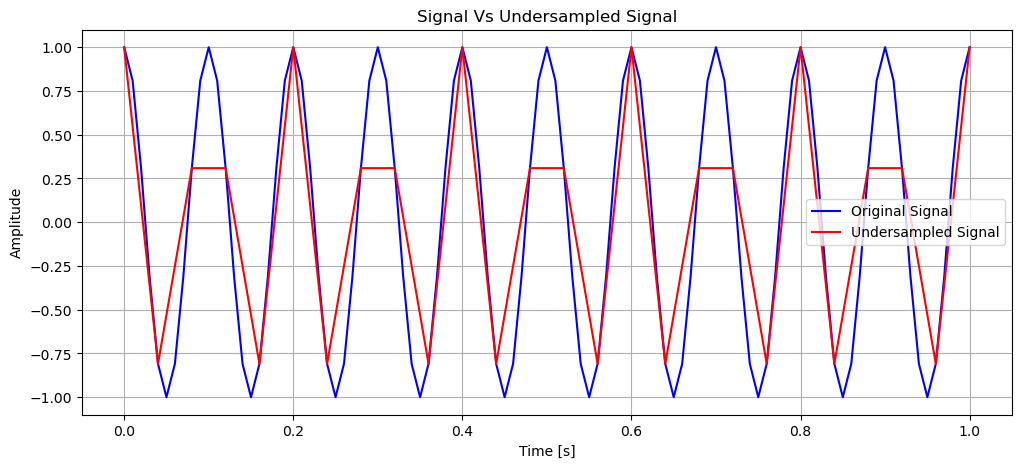

In [24]:
plt.figure(figsize=(12, 5))
plt.plot(time, cos_function, label='Original Signal', color='blue')
plt.plot(time_undersampled, cos_function_undersampled, label='Undersampled Signal', color='red')
plt.title('Signal Vs Undersampled Signal')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.grid()
plt.show()

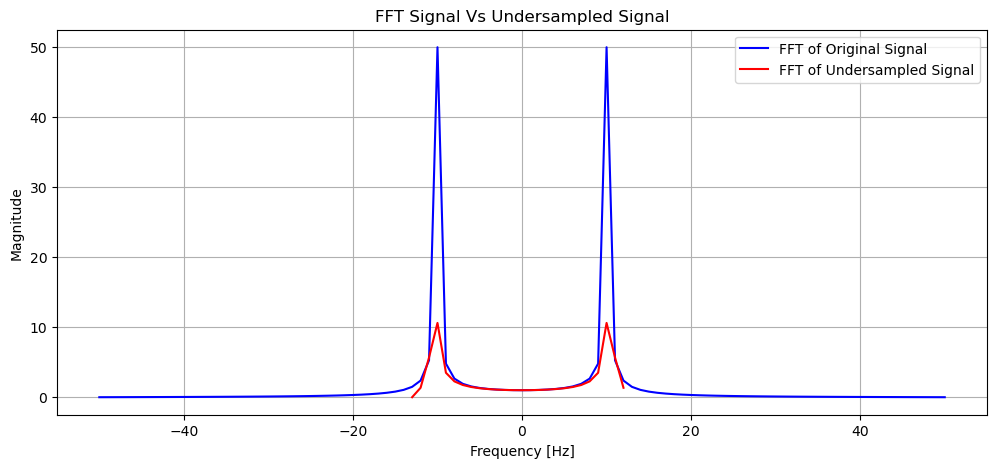

In [25]:
plt.figure(figsize=(12, 5))
plt.plot(fftshift(fftfreq(samples, d=1/samples)), fftshift(np.abs(fft(cos_function))), label='FFT of Original Signal', color='blue')
plt.plot(fftshift(fftfreq(samples_undersampled, d=1/samples_undersampled)), fftshift(np.abs(fft(cos_function_undersampled))), label='FFT of Undersampled Signal', color='red')
plt.title('FFT Signal Vs Undersampled Signal')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.grid()
plt.legend()
plt.show()

In [26]:
def zero_stuffing(rf_matrices_summed, interpolation_factor):
    interpolation_factor = interpolation_factor - 1
    new_array_length = rf_matrices_summed.shape[0] + interpolation_factor * (rf_matrices_summed.shape[0] - 1)
    new_rf_matrices_summed = np.zeros(new_array_length)
    for k in range(rf_matrices_summed.shape[0]): #for each sample
        idx_new = k + (interpolation_factor * k)
        new_rf_matrices_summed[idx_new] = rf_matrices_summed[k]

    return new_rf_matrices_summed, new_array_length

In [27]:
zero_stuffed_cos, new_array_length = zero_stuffing(cos_function_undersampled, interpolation_factor)

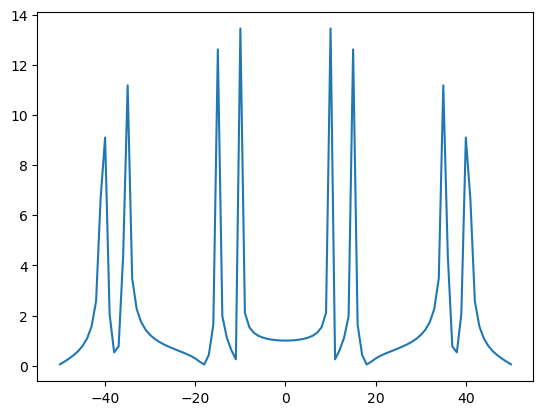

In [28]:
plt.plot(fftshift(fftfreq(zero_stuffed_cos.shape[0], d=1/zero_stuffed_cos.shape[0])), fftshift(np.abs(fft(zero_stuffed_cos))))

In [29]:
def get_filtered_matrices(zero_stuffed_rf_matrices_summed):
    new_samples = zero_stuffed_rf_matrices_summed.shape[0]
    
    #cutoff_freq = 0.50 * 10 #use Nyquist frequency as cutoff frequency
    fs_new = fs_undersampled * interpolation_factor

    cutoff_freq = fs_undersampled * 0.5
    
    num_taps = 40

    if num_taps % 2 == 0:
        num_taps += 1
    if num_taps >= new_samples:
        print(f"Warning: num_taps ({num_taps}) >= signal length ({new_samples}). Reducing.")
        num_taps = new_samples - 1 if (new_samples - 1) % 2 != 0 else new_samples - 2
        if num_taps < 1: num_taps = 1

    if not (0 < cutoff_freq < fs / 2.0):
         raise ValueError(f"Calculated cutoff frequency {cutoff_freq} is invalid for fs_new/2 = {fs_new/2.0}")

    filtered_rf_matrices_summed = np.zeros((new_samples))
    filtered_rf_matrices_summed2 = np.zeros((num_taps))

    # cutoff_hz = Fs_original / 2 = (Fs_new / L) / 2
    
    time = np.linspace(-new_samples/2 * 1/new_samples, new_samples/2 * 1/new_samples, new_samples) 
    
    filtering_function = np.sinc(2 *np.pi * cutoff_freq * time) * interpolation_factor
    
    filtering_function2 = signal.firwin(num_taps, cutoff_freq, fs=fs_new, window='hamming', pass_zero='lowpass') * interpolation_factor


    # filtering_function = filtering_function / new_samples / 2
    
    # (convolution in time domain = multiplication in frequency domain)
    filtered_rf_matrices_summed = np.convolve(zero_stuffed_rf_matrices_summed, filtering_function, mode='same')
    filtered_rf_matrices_summed2 = np.convolve(zero_stuffed_rf_matrices_summed, filtering_function2, mode='same')
    
    # fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize=(12, 8))

    # axes[0,0].plot(fftshift(fftfreq(new_samples, d=1/new_samples)), fftshift(np.abs(fft(filtering_function))), label='Filter Response')
    # axes[0,0].plot(fftshift(fftfreq(new_samples, d=1/new_samples)), fftshift(np.abs(fft(zero_stuffed_rf_matrices_summed))), label='Original Signal')
    # axes[0,0].set_title('Frequency Domain')
    
    # axes[0,1].plot(fftshift(fftfreq(new_samples, d=1/new_samples)), fftshift(np.abs(fft(filtered_rf_matrices_summed))), label='Filtered Signal')
    # axes[0,1].set_title('Filtered Result')

    # axes[1,0].plot(fftshift(fftfreq(num_taps, d=1/num_taps)), fftshift(np.abs(fft(filtering_function2))), label='Filter Response')
    # axes[1,0].plot(fftshift(fftfreq(num_taps, d=1/num_taps)), fftshift(np.abs(fft(filtered_rf_matrices_summed2))), label='Original Signal')
    # axes[1,0].set_title('Frequency Domain')
    
    # axes[1,1].plot(fftshift(fftfreq(num_taps, d=1/num_taps)), fftshift(np.abs(fft(filtered_rf_matrices_summed2))), label='Filtered Signal')
    # axes[1,1].set_title('Filtered Result')

    # fig.tight_layout()
    # fig.legend()
    # fig.show()
    
    return filtered_rf_matrices_summed, filtered_rf_matrices_summed2

In [30]:

filtered_cos, filtered_cos2  = get_filtered_matrices(zero_stuffed_cos)

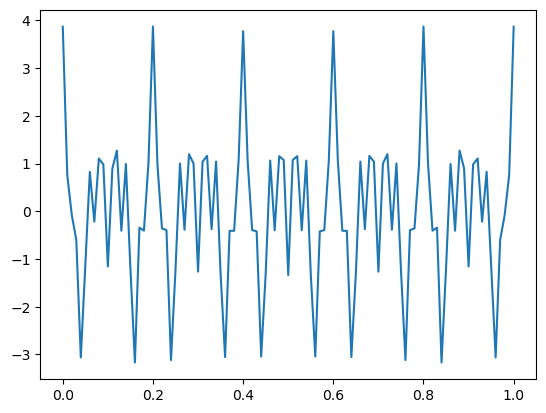

In [31]:
plt.plot(time, filtered_cos)

In [32]:
time_test = np.linspace(0, 1, 101)

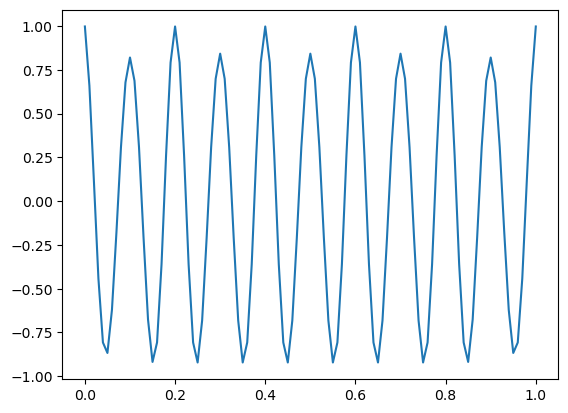

In [33]:
plt.plot(time_test, filtered_cos2)	

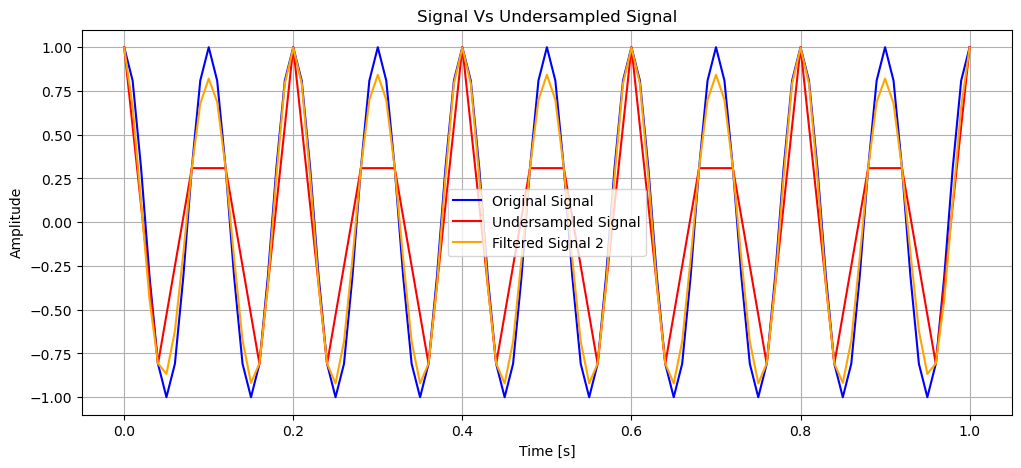

In [34]:
plt.figure(figsize=(12, 5))
plt.plot(time, cos_function, label='Original Signal', color='blue')
plt.plot(time_undersampled, cos_function_undersampled, label='Undersampled Signal', color='red')
# plt.plot(time, filtered_cos, label='Filtered Signal', color='green')
plt.plot(time_test, filtered_cos2, label='Filtered Signal 2', color='orange')
plt.title('Signal Vs Undersampled Signal')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.grid()
plt.show()